# 2.4. Анализ факторов интереса к видеоиграм

В качестве двух показателей интереса аудитории используются число рекомендаций Steam и среднее число игроков за последние 12 месяцев, доступных в Steam Monthly Players.

Проверяются связи этих показателей с ценой, годом выхода и основным жанром игры. Нулевая гипотеза предполагает отсутствие статистической связи и различий между жанрами. Альтернативная гипотеза предполагает наличие хотя бы одной связи или различия.

Анализ выявляет статистические ассоциации и не доказывает причинное влияние. Межплатформенные совпадения по названиям в основной модели не используются.

In [1]:
from pathlib import Path
import json
import time

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import kruskal, spearmanr
from IPython.display import display

import re
from scipy.sparse import load_npz

ROOT = next(
    (
        path
        for path in [Path.cwd(), *Path.cwd().parents]
        if (path / "notebooks").is_dir() and (path / "README.md").exists()
    ),
    None,
)

if ROOT is None:
    raise FileNotFoundError("Не удалось найти корень проекта.")

STEAM_PATH = ROOT / "processed" / "games" / "steam_games.parquet"
DATABASE_PATH = ROOT / "warehouse" / "games.duckdb"
OUTPUT_DIR = ROOT / "processed" / "analysis"
QUALITY_DIR = ROOT / "docs" / "data_quality"

for path in [STEAM_PATH, DATABASE_PATH]:
    if not path.is_file():
        raise FileNotFoundError(f"Сначала запусти 2_3: {path}")

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
QUALITY_DIR.mkdir(parents=True, exist_ok=True)

analysis_start = time.perf_counter()

print("Корень проекта:", ROOT)

Корень проекта: C:\Users\Daniil\Documents\GitHub\gaming-data-analysis


## Подготовка игровой таблицы

Steam Monthly Players агрегируется по AppID за последние 12 месяцев, доступных в наборе. Благодаря этому к каталогу Steam присоединяется не более одной строки на игру.

Для каждого анализа ниже используются только записи без пропусков в нужных ему полях. Пропуски не заменяются нулями.

In [2]:
steam = pd.read_parquet(
    STEAM_PATH,
    columns=[
        "AppID", "name", "release_date", "price",
        "genres", "positive", "negative", "recommendations",
    ],
)
steam["AppID"] = steam["AppID"].astype("string")
steam["price"] = pd.to_numeric(steam["price"], errors="coerce")
steam["recommendations"] = pd.to_numeric(
    steam["recommendations"], errors="coerce"
)
steam["release_year"] = pd.to_datetime(
    steam["release_date"], errors="coerce"
).dt.year


def get_primary_genre(value):
    if not isinstance(value, str) or not value.strip():
        return None

    try:
        genres = json.loads(value)
    except json.JSONDecodeError:
        genres = value.split(",")

    if isinstance(genres, list) and genres:
        return str(genres[0]).strip() or None

    return None


steam["primary_genre"] = steam["genres"].map(get_primary_genre)

connection = duckdb.connect(str(DATABASE_PATH), read_only=True)

try:
    latest_month = connection.execute(
        "SELECT MAX(month) FROM steam_monthly_players"
    ).fetchone()[0]

    window_end = pd.Timestamp(latest_month)
    window_start = window_end - pd.DateOffset(months=11)

    monthly_players = connection.execute(
        """
        SELECT
            CAST(steam_appid AS VARCHAR) AS AppID,
            AVG(avg_players) AS avg_players_12m,
            COUNT(DISTINCT month) AS months_observed
        FROM steam_monthly_players
        WHERE month BETWEEN ? AND ?
        GROUP BY steam_appid
        """,
        [window_start.to_pydatetime(), window_end.to_pydatetime()],
    ).fetchdf()
finally:
    connection.close()

monthly_players["AppID"] = monthly_players["AppID"].astype("string")

analysis_df = steam.merge(
    monthly_players,
    on="AppID",
    how="left",
    validate="one_to_one",
)

reviews_total = analysis_df["positive"] + analysis_df["negative"]
analysis_df["positive_share"] = (
    analysis_df["positive"] / reviews_total.where(reviews_total > 0)
)

analysis_df.to_parquet(
    OUTPUT_DIR / "steam_game_analysis_2_4.parquet",
    index=False,
    compression="zstd",
)

print("Игр в каталоге Steam:", f"{len(analysis_df):,}")
print("Игр с данными игроков за период:", f"{analysis_df['avg_players_12m'].notna().sum():,}")
print("Окно Steam Monthly Players:", window_start.date(), "—", window_end.date())

display(
    analysis_df[
        [
            "price", "release_year", "primary_genre",
            "recommendations", "avg_players_12m", "positive_share",
        ]
    ].isna().sum().rename("missing_values").to_frame()
)

Игр в каталоге Steam: 150,466
Игр с данными игроков за период: 4,336
Окно Steam Monthly Players: 2024-10-01 — 2025-09-01


,missing_values
price,0
release_year,0
primary_genre,8437
recommendations,0
avg_players_12m,146130
positive_share,67380


In [3]:
month_counts = (
    analysis_df["months_observed"]
    .value_counts()
    .reindex(range(1, 13), fill_value=0)
    .rename_axis("months_observed")
    .reset_index(name="games")
)

display(month_counts)

analysis_df["avg_players_available_months"] = analysis_df["avg_players_12m"]
analysis_df["avg_players_12m"] = analysis_df["avg_players_12m"].where(
    analysis_df["months_observed"] >= 9
)

analysis_df.to_parquet(
    OUTPUT_DIR / "steam_game_analysis_2_4.parquet",
    index=False,
    compression="zstd",
)

print(
    "Игр с данными минимум за 9 из 12 месяцев:",
    int(analysis_df["avg_players_12m"].notna().sum()),
)

,months_observed,games
0,1,206
1,2,129
2,3,79
3,4,77
4,5,63
5,6,68
6,7,88
7,8,69
8,9,74
9,10,105


Игр с данными минимум за 9 из 12 месяцев: 3557


## Habr: тематический контекст и NLP

Две статьи Habr используются как небольшой иллюстративный корпус. Для каждой статьи рассчитываются объём текста, число уникальных слов и количество числовых упоминаний; по TF-IDF выводятся наиболее характерные термины.

Для сопоставления с первой статьёй отдельно рассчитывается доля игр Steam с нулём рекомендаций среди релизов 2021–2025 годов. Это сравнение разных наборов данных, а не независимое подтверждение результата статьи. Две публикации не являются репрезентативной выборкой и не позволяют делать выводы обо всём игровом рынке.

Первая статья сообщает, что в использованном авторами наборе за 2021–2025 годы 87,5% игр не получили рекомендаций. [Статья на Habr](https://habr.com/ru/articles/995396/)

Вторая статья приводит результаты исследования игровой аудитории России; среди прочего в ней сообщается о 75% играющих среди населения от 14 лет. Эти результаты характеризуют опросную аудиторию России и напрямую не сопоставляются с каталогом игр Steam. [Статья на Habr](https://habr.com/ru/articles/990554/)

In [4]:
TEXT_DIR = ROOT / "processed" / "text"

habr = pd.read_parquet(TEXT_DIR / "habr_articles.parquet")
document_ids = pd.read_csv(TEXT_DIR / "habr_tfidf_documents.csv")
vocabulary = (
    pd.read_csv(TEXT_DIR / "habr_tfidf_vocabulary.csv")
    .set_index("feature_index")["term"]
)
tfidf = load_npz(TEXT_DIR / "habr_tfidf.npz")

if tfidf.shape[0] != len(document_ids):
    raise ValueError("Число документов не совпадает с размером TF-IDF матрицы.")

habr = (
    habr.set_index("url")
    .loc[document_ids["url"]]
    .reset_index()
)

article_metrics = []
term_rows = []

for index, article in habr.iterrows():
    tokens = re.findall(
        r"\b[а-яёa-z]{3,}\b",
        str(article["clean_text"]).casefold(),
    )
    numbers = re.findall(
        r"\d+(?:[,.]\d+)?\s*%?",
        str(article["text"]),
    )

    article_metrics.append({
        "url": article["url"],
        "title": article["title"],
        "words": len(tokens),
        "unique_words": len(set(tokens)),
        "numeric_mentions": len(numbers),
    })

    row = tfidf.getrow(index)
    top_positions = row.data.argsort()[::-1][:10]

    for position in top_positions:
        feature_index = int(row.indices[position])
        term_rows.append({
            "url": article["url"],
            "title": article["title"],
            "term": vocabulary.loc[feature_index],
            "tfidf": float(row.data[position]),
        })

habr_metrics = pd.DataFrame(article_metrics)
habr_terms = pd.DataFrame(term_rows)

# TF-IDF использует L2-нормировку, поэтому скалярное произведение
# двух строк равно косинусному сходству.
cosine_similarity = float(tfidf[0].multiply(tfidf[1]).sum())

habr_metrics.to_csv(
    QUALITY_DIR / "habr_text_metrics_2_4.csv",
    index=False,
    encoding="utf-8-sig",
)
habr_terms.to_csv(
    QUALITY_DIR / "habr_tfidf_terms_2_4.csv",
    index=False,
    encoding="utf-8-sig",
)

steam_window = analysis_df.dropna(
    subset=["release_year", "recommendations"]
)
steam_window = steam_window[
    steam_window["release_year"].between(2021, 2025)
    & (steam_window["recommendations"] >= 0)
]

steam_zero_share = (
    100 * steam_window["recommendations"].eq(0).mean()
    if len(steam_window)
    else np.nan
)

habr_comparison = pd.DataFrame([
    {
        "source": "Habr, статья о Steam",
        "release_period": "2021–2025",
        "games": "около 65 000 по описанию статьи",
        "zero_recommendations_pct": 87.5,
        "url": "https://habr.com/ru/articles/995396/",
    },
    {
        "source": "Steam Games Dataset",
        "release_period": "2021–2025",
        "games": len(steam_window),
        "zero_recommendations_pct": steam_zero_share,
        "url": "",
    },
])

habr_comparison.to_csv(
    QUALITY_DIR / "habr_steam_comparison_2_4.csv",
    index=False,
    encoding="utf-8-sig",
)

display(habr_metrics)
display(habr_terms.groupby("title", group_keys=False).head(10))
display(habr_comparison)
print(f"Косинусное сходство статей по TF-IDF: {cosine_similarity:.3f}")

,url,title,words,unique_words,numeric_mentions
0,https://habr.com/ru/articles/995396/,"Только 12,5% игр в Steam получают пользователь...",642,438,43
1,https://habr.com/ru/articles/990554/,От ниши к мейнстриму: с 33 до 75% за 5 лет. Ка...,1467,939,123


,url,title,term,tfidf
0,https://habr.com/ru/articles/995396/,"Только 12,5% игр в Steam получают пользователь...",рекомендаций,0.111732
1,https://habr.com/ru/articles/995396/,"Только 12,5% игр в Steam получают пользователь...",steam,0.080775
2,https://habr.com/ru/articles/995396/,"Только 12,5% игр в Steam получают пользователь...",релиза,0.077283
3,https://habr.com/ru/articles/995396/,"Только 12,5% игр в Steam получают пользователь...",количество,0.077283
4,https://habr.com/ru/articles/995396/,"Только 12,5% игр в Steam получают пользователь...",игр,0.076684
5,https://habr.com/ru/articles/995396/,"Только 12,5% игр в Steam получают пользователь...",старт,0.070674
6,https://habr.com/ru/articles/995396/,"Только 12,5% игр в Steam получают пользователь...",первые,0.070674
7,https://habr.com/ru/articles/995396/,"Только 12,5% игр в Steam получают пользователь...",рынок,0.067374
8,https://habr.com/ru/articles/995396/,"Только 12,5% игр в Steam получают пользователь...",если,0.067374
9,https://habr.com/ru/articles/995396/,"Только 12,5% игр в Steam получают пользователь...",получает,0.062154


,source,release_period,games,zero_recommendations_pct,url
0,"Habr, статья о Steam",2021–2025,около 65 000 по описанию статьи,87.500000,https://habr.com/ru/articles/995396/
1,Steam Games Dataset,2021–2025,82998,87.702113,


Косинусное сходство статей по TF-IDF: 0.053


Числовые характеристики и TF-IDF показывают, какие темы и числовые утверждения встречаются в этих двух статьях. При столь малом корпусе TF-IDF используется только для иллюстрации тематических различий; это не тематическая модель рынка и не оценка общественного мнения.

Сравнение доли игр без рекомендаций с числом из первой статьи следует интерпретировать осторожно: источники, правила отбора и снимки данных различаются. Результат нужен для сопоставления контекста, а не для репликации исследования.

## Объединённый профиль игры

Для сопоставимого представления используется Steam AppID. В профиль включается одна строка на игру: показатели Steam остаются на уровне игры, Wikidata агрегируется по URI сущности, Twitch — по названию игры за весь доступный период, YouTube — по поисковому запросу, RAWG — по уникальному кандидату сопоставления.

Связи RAWG, Wikidata и Twitch основаны на нормализованных названиях. Они остаются непроверенными кандидатами. YouTube `game_name` — название поискового запроса, а не подтверждение содержания каждого видео. Разные временные периоды источников не объединяются в общий временной ряд.

In [5]:
MAPPING_PATH = ROOT / "processed" / "games" / "game_source_mapping.parquet"

mapping = pd.read_parquet(MAPPING_PATH)
mapping["steam_app_id"] = mapping["steam_app_id"].astype("string")
mapping["source_game_id"] = mapping["source_game_id"].astype("string")

profile = analysis_df[
    [
        "AppID", "name", "release_year", "primary_genre", "price",
        "recommendations", "positive_share", "avg_players_12m",
    ]
].rename(columns={"AppID": "steam_app_id"}).copy()

profile["steam_app_id"] = profile["steam_app_id"].astype("string")


def attach_source(source_name, details, detail_key, output_columns):
    links = mapping.loc[
        mapping["source"].eq(source_name),
        ["steam_app_id", "source_game_id"],
    ].copy()

    links["source_game_id"] = links["source_game_id"].astype("string")
    details = details.copy()
    details[detail_key] = details[detail_key].astype("string")

    linked = links.merge(
        details,
        left_on="source_game_id",
        right_on=detail_key,
        how="inner",
        validate="one_to_one",
    )

    return linked[["steam_app_id", *output_columns]]


# RAWG: к Steam присоединяются только уникальные кандидаты из crosswalk.
rawg = pd.read_parquet(
    ROOT / "processed" / "games" / "rawg_games.parquet",
    columns=["id", "rating", "ratings_count", "metacritic"],
).rename(columns={
    "id": "rawg_id",
    "rating": "rawg_rating",
    "ratings_count": "rawg_ratings_count",
    "metacritic": "rawg_metacritic",
})

rawg_links = attach_source(
    "RAWG",
    rawg,
    "rawg_id",
    ["rawg_id", "rawg_rating", "rawg_ratings_count", "rawg_metacritic"],
)
profile = profile.merge(
    rawg_links, on="steam_app_id", how="left", validate="one_to_one"
)

# Wikidata: сначала сводим повторные строки SPARQL к одной строке на URI.
wikidata = pd.read_parquet(
    ROOT / "processed" / "games" / "wikidata_games.parquet"
)
wikidata["release_year"] = pd.to_datetime(
    wikidata["releaseDate"], errors="coerce", utc=True
).dt.year


def join_labels(values):
    return " | ".join(sorted({
        str(value).strip()
        for value in values.dropna()
        if str(value).strip()
    }))


wikidata_entities = (
    wikidata.groupby("game", as_index=False)
    .agg(
        wikidata_name=("gameLabel", "first"),
        wikidata_release_year_min=("release_year", "min"),
        wikidata_release_year_max=("release_year", "max"),
        wikidata_genres=("genreLabel", join_labels),
        wikidata_platforms=("platformLabel", join_labels),
        wikidata_developers=("developerLabel", join_labels),
        wikidata_publishers=("publisherLabel", join_labels),
        wikidata_source_rows=("gameLabel", "size"),
    )
)

wikidata_entities.to_csv(
    QUALITY_DIR / "wikidata_entity_profile_2_4.csv",
    index=False,
    encoding="utf-8-sig",
)

wikidata_links = attach_source(
    "Wikidata",
    wikidata_entities,
    "game",
    [
        "game", "wikidata_name", "wikidata_release_year_min",
        "wikidata_release_year_max", "wikidata_genres",
        "wikidata_platforms", "wikidata_developers",
        "wikidata_publishers", "wikidata_source_rows",
    ],
).rename(columns={"game": "wikidata_uri"})

profile = profile.merge(
    wikidata_links, on="steam_app_id", how="left", validate="one_to_one"
)

# Twitch: удаляем повторные строки игры за месяц перед агрегацией.
twitch = pd.read_parquet(
    ROOT / "processed" / "twitch" / "twitch_games.parquet"
)
twitch_month_key = ["Game", "Year", "Month"]
twitch_duplicate_rows = int(twitch.duplicated(twitch_month_key).sum())

twitch_monthly = (
    twitch.sort_values("Rank")
    .drop_duplicates(twitch_month_key)
)

twitch_summary = (
    twitch_monthly.groupby("Game", as_index=False)
    .agg(
        twitch_months=("Month", "size"),
        twitch_year_start=("Year", "min"),
        twitch_year_end=("Year", "max"),
        twitch_hours_watched=("Hours_watched", "sum"),
        twitch_avg_viewers=("Avg_viewers", "mean"),
        twitch_peak_viewers=("Peak_viewers", "max"),
    )
)

twitch_links = mapping.loc[
    mapping["source"].eq("Twitch"),
    ["steam_app_id", "source_game_name"],
].drop_duplicates()

twitch_links = twitch_links.merge(
    twitch_summary,
    left_on="source_game_name",
    right_on="Game",
    how="inner",
    validate="one_to_one",
).drop(columns=["source_game_name", "Game"])

profile = profile.merge(
    twitch_links, on="steam_app_id", how="left", validate="one_to_one"
)

# YouTube связывается только с однозначными названиями поисковых запросов.
steam_names = profile[["steam_app_id", "name"]].dropna().drop_duplicates()
name_counts = steam_names.groupby("name")["steam_app_id"].nunique()
unique_names = name_counts[name_counts.eq(1)].index
steam_names = steam_names[steam_names["name"].isin(unique_names)]

youtube = pd.read_parquet(
    ROOT / "processed" / "youtube" / "youtube_search_rows.parquet"
).drop_duplicates(["game_name", "video_id"])

youtube_linked = youtube.merge(
    steam_names,
    left_on="game_name",
    right_on="name",
    how="inner",
    validate="many_to_one",
)

youtube_summary = (
    youtube_linked.groupby("steam_app_id", as_index=False)
    .agg(
        youtube_video_count=("video_id", "nunique"),
        youtube_median_views=("views", "median"),
        youtube_median_likes=("likes", "median"),
        youtube_median_comments=("comments", "median"),
    )
)

profile = profile.merge(
    youtube_summary, on="steam_app_id", how="left", validate="one_to_one"
)

profile["external_sources_present"] = profile[
    ["rawg_id", "wikidata_uri", "twitch_hours_watched", "youtube_video_count"]
].notna().sum(axis=1)

OUTPUT_PROFILE = OUTPUT_DIR / "cross_source_game_profile_2_4.parquet"
profile.to_parquet(OUTPUT_PROFILE, index=False, compression="zstd")

coverage_specs = [
    ("RAWG", "rawg_id", "Уникальное совпадение названия; не подтверждено"),
    ("Wikidata", "wikidata_uri", "Уникальное совпадение названия; не подтверждено"),
    ("Twitch", "twitch_hours_watched", "Агрегат за доступные годы Twitch; период отличается"),
    ("YouTube", "youtube_video_count", "Совпадает поисковый запрос; тема видео не подтверждена"),
]

coverage = pd.DataFrame([
    {
        "source": source,
        "linked_steam_games": int(profile[column].notna().sum()),
        "steam_catalog_games": len(profile),
        "coverage_percent": round(
            100 * profile[column].notna().mean(), 2
        ),
        "interpretation": note,
    }
    for source, column, note in coverage_specs
])

coverage.to_csv(
    QUALITY_DIR / "cross_source_coverage_2_4.csv",
    index=False,
    encoding="utf-8-sig",
)

connection = duckdb.connect(str(DATABASE_PATH))
try:
    connection.register("profile_df", profile)
    connection.execute("""
        CREATE OR REPLACE TABLE cross_source_game_profile AS
        SELECT * FROM profile_df
    """)
finally:
    connection.close()

print("Размер объединённого профиля:", f"{len(profile):,} игр")
print("Повторных Twitch-строк по ключу игра-год-месяц:", twitch_duplicate_rows)
display(coverage)
display(
    profile.loc[profile["external_sources_present"] > 0]
    .sort_values("external_sources_present", ascending=False)
    .head(10)
)

Размер объединённого профиля: 150,466 игр
Повторных Twitch-строк по ключу игра-год-месяц: 10


,source,linked_steam_games,steam_catalog_games,coverage_percent,interpretation
0,RAWG,102889,150466,68.38,Уникальное совпадение названия; не подтверждено
1,Wikidata,3,150466,0.00,Уникальное совпадение названия; не подтверждено
2,Twitch,1263,150466,0.84,Агрегат за доступные годы Twitch; период отлич...
3,YouTube,29,150466,0.02,Совпадает поисковый запрос; тема видео не подт...


,steam_app_id,name,release_year,primary_genre,price,recommendations,positive_share,avg_players_12m,rawg_id,rawg_rating,...,twitch_year_start,twitch_year_end,twitch_hours_watched,twitch_avg_viewers,twitch_peak_viewers,youtube_video_count,youtube_median_views,youtube_median_likes,youtube_median_comments,external_sources_present
10927,105600,Terraria,2011,Action,4.99,1163012,0.974818,25960.340833,422,4.08,...,2016.0,2024.0,9.319773e+07,1431.123596,265103.0,10.0,2209758.0,63806.0,394.5,3
44134,2358720,Black Myth: Wukong,2024,Action,59.99,863021,0.966631,NaN,481913,4.30,...,2024.0,2024.0,3.974951e+07,26984.500000,484173.0,10.0,3056260.5,50986.5,1447.5,3
35552,362890,Black Mesa,2020,Action,4.99,128047,0.951986,982.435000,15426,4.35,...,2019.0,2020.0,1.516286e+06,1020.000000,35028.0,NaN,NaN,NaN,NaN,3
4117,1097150,Fall Guys,2020,Action,0.00,414355,0.813002,NaN,510356,2.57,...,2022.0,2024.0,1.820166e+08,7536.242424,417781.0,10.0,1421679.0,11640.0,474.0,3
45509,730,Counter-Strike 2,2012,Action,0.00,4830455,0.866932,951811.999167,965470,3.59,...,2023.0,2023.0,9.973671e+06,4531.333333,138445.0,10.0,1209523.5,16506.0,370.5,3
14153,346110,ARK: Survival Evolved,2017,Action,9.89,567077,0.838403,23866.185833,9810,3.08,...,2016.0,2023.0,8.157150e+07,5067.727273,174919.0,10.0,511581.0,11454.0,345.0,3
39800,292030,The Witcher 3: Wild Hunt,2015,RPG,3.99,797928,0.961266,14882.770833,3328,4.64,...,2016.0,2024.0,9.069273e+07,1410.875000,88802.0,10.0,2937469.5,49297.0,3968.5,3
47023,381210,Dead by Daylight,2016,Action,7.99,629323,0.790530,43174.814167,9966,3.50,...,2016.0,2024.0,1.400273e+09,19182.110000,256602.0,10.0,392785.5,11383.5,378.5,3
3692,218620,PAYDAY 2,2013,Action,0.99,439326,0.896310,20474.426667,3939,3.52,...,2016.0,2017.0,1.943799e+06,221.166667,36544.0,10.0,2349173.0,35060.0,796.0,3
45588,739630,Phasmophobia,2020,Action,13.99,653403,0.958157,16028.710000,427930,3.85,...,2020.0,2024.0,2.221372e+08,6196.163265,256449.0,10.0,1921543.0,41917.5,399.0,3


Таблица `cross_source_game_profile` содержит одну строку на Steam AppID и отдельные агрегированные показатели источников. Она предназначена для описательного сопоставления и визуализации. Связи по названиям не являются подтверждёнными идентификаторами.

Wikidata содержит повторные строки по одной сущности из-за нескольких дат и характеристик. Поэтому свойства сначала агрегируются по URI игры. В текущем сопоставлении Wikidata с каталогом Steam мало уникальных связей; эти строки используются как примеры обогащения метаданных, а не как основа для статистического теста. Twitch и Steam Monthly Players покрывают разные временные интервалы, а YouTube хранит поисковые результаты, поэтому их показатели нельзя считать синхронными измерениями интереса.

## Подготовка таблицы на RAWG

In [6]:
from scipy.stats import kruskal, spearmanr

def format_p_value(value):
    return "< 1e-300" if value == 0 else f"{value:.3g}"

RAWG_PATH = ROOT / "processed" / "games" / "rawg_games.parquet"

rawg = pd.read_parquet(
    RAWG_PATH,
    columns=["id", "name", "released", "rating", "ratings_count", "genres"],
)

rawg["release_year"] = pd.to_datetime(
    rawg["released"], errors="coerce"
).dt.year
rawg["rating"] = pd.to_numeric(rawg["rating"], errors="coerce")
rawg["ratings_count"] = pd.to_numeric(
    rawg["ratings_count"], errors="coerce"
)


def first_rawg_genre(value):
    if not isinstance(value, str) or not value.strip():
        return None

    try:
        genres = json.loads(value)
    except json.JSONDecodeError:
        genres = value.split("|")

    if isinstance(genres, list) and genres:
        first = genres[0]
        if isinstance(first, dict):
            return first.get("name")
        return str(first).strip() or None

    return None


rawg["primary_genre"] = rawg["genres"].map(first_rawg_genre)

rawg_games = rawg.dropna(subset=["ratings_count"]).copy()
rawg_games = rawg_games[rawg_games["ratings_count"] >= 0]

print(f"RAWG: {len(rawg):,} игр в каталоге")
print(f"RAWG: {len(rawg_games):,} игр с известным числом оценок")
print(f"RAWG: {(rawg_games['ratings_count'] > 0).sum():,} игр хотя бы с одной оценкой")

rawg_correlations = []

for feature in ["release_year", "rating"]:
    sample = rawg_games[[feature, "ratings_count"]].dropna()

    if len(sample) >= 3:
        rho, p_value = spearmanr(sample[feature], sample["ratings_count"])
        rawg_correlations.append({
            "feature": feature,
            "target": "ratings_count",
            "n": len(sample),
            "spearman_rho": rho,
            "p_value_display": format_p_value(p_value),
        })

rawg_correlations = pd.DataFrame(rawg_correlations)
rawg_correlations.to_csv(
    QUALITY_DIR / "rawg_correlations_2_4.csv",
    index=False,
    encoding="utf-8-sig",
)

rawg_genres = rawg_games.dropna(subset=["primary_genre"]).copy()
rawg_genres["has_ratings"] = rawg_genres["ratings_count"] > 0

rawg_genre_summary = (
    rawg_genres.groupby("primary_genre")
    .agg(
        games=("ratings_count", "size"),
        zero_share=("has_ratings", lambda values: 1 - values.mean()),
        median_all=("ratings_count", "median"),
    )
)

rawg_positive = rawg_genres[rawg_genres["ratings_count"] > 0]
rawg_positive_summary = (
    rawg_positive.groupby("primary_genre")["ratings_count"]
    .agg(positive_games="size", median_positive="median")
)

rawg_genre_summary = rawg_genre_summary.join(rawg_positive_summary)
rawg_genre_summary = rawg_genre_summary[
    rawg_genre_summary["games"] >= 100
].sort_values("games", ascending=False)

rawg_genre_groups = [
    np.log1p(group.loc[group["ratings_count"] > 0, "ratings_count"])
    .to_numpy()
    for _, group in rawg_genres.groupby("primary_genre")
    if (group["ratings_count"] > 0).sum() >= 30
]

if len(rawg_genre_groups) >= 2:
    statistic, p_value = kruskal(*rawg_genre_groups)
    rawg_genre_test = pd.DataFrame([{
        "groups_tested": len(rawg_genre_groups),
        "kruskal_statistic": statistic,
        "p_value_display": format_p_value(p_value),
    }])
else:
    rawg_genre_test = pd.DataFrame()

rawg_genre_summary.to_csv(
    QUALITY_DIR / "rawg_genre_summary_2_4.csv",
    encoding="utf-8-sig",
)
rawg_genre_test.to_csv(
    QUALITY_DIR / "rawg_genre_test_2_4.csv",
    index=False,
    encoding="utf-8-sig",
)

display(rawg_correlations)
display(rawg_genre_test)
display(rawg_genre_summary.head(10))

RAWG: 899,585 игр в каталоге
RAWG: 66,405 игр с известным числом оценок
RAWG: 66,405 игр хотя бы с одной оценкой


,feature,target,n,spearman_rho,p_value_display
0,release_year,ratings_count,62929,-0.235037,< 1e-300
1,rating,ratings_count,18675,0.208670,8.49e-183


,groups_tested,kruskal_statistic,p_value_display
0,19,2890.087564,< 1e-300


,games,zero_share,median_all,positive_games,median_positive
primary_genre,,,,,
Action,22558,0.0,3.0,22558,3.0
Adventure,11335,0.0,2.0,11335,2.0
Strategy,5087,0.0,2.0,5087,2.0
RPG,4890,0.0,2.0,4890,2.0
Simulation,3440,0.0,2.0,3440,2.0
Casual,2424,0.0,2.0,2424,2.0
Arcade,1983,0.0,2.0,1983,2.0
Sports,1573,0.0,2.0,1573,2.0
Puzzle,1450,0.0,1.0,1450,1.0


### Выводы по RAWG

RAWG добавляет крупный каталог, но число оценок известно только для части записей. Поэтому анализ популярности проведён на играх с заполненным `ratings_count`; пропуски не интерпретировались как нулевой интерес.

Связь числа оценок с годом выпуска и пользовательским рейтингом оценена корреляцией Спирмена. Результаты отражают ассоциации внутри RAWG и не доказывают причинного влияния.

Между жанровыми группами проверены различия в числе оценок среди игр, у которых оно больше нуля. Критерий Краскела — Уоллиса показывает, есть ли различия между группами в целом, но не определяет, какие именно пары жанров отличаются.

Результаты RAWG не объединяются с результатами Steam: межплатформенные совпадения по названию в `2_3` являются непроверенными кандидатами. Поэтому число строк RAWG и Steam нельзя складывать и трактовать как число уникальных игр.

## Описательный и статистический анализ

Корреляция Спирмена используется для оценки монотонных связей, менее чувствительных к сильной асимметрии показателей популярности. Для сравнения жанров применяется критерий Краскела — Уоллиса. В каждой игре для группировки используется первый жанр из исходного списка.

,feature,target,n,spearman_rho,p_value,p_value_display
0,price,recommendations,150466,0.208232,0.000000e+00,< 1e-300
1,release_year,recommendations,150466,-0.244662,0.000000e+00,< 1e-300
2,positive_share,recommendations,83086,0.042311,3.054672e-34,3.05e-34
3,price,avg_players_12m,3557,0.093405,2.391420e-08,2.39e-08
4,release_year,avg_players_12m,3557,0.101748,1.187181e-09,1.19e-09
5,positive_share,avg_players_12m,3543,0.209344,2.214563e-36,2.21e-36


,groups_tested,kruskal_statistic,p_value,p_value_display
0,12,608.277315,2.375074e-123,2.38e-123


,games,zero_share,median_all,positive_games,median_positive
primary_genre,,,,,
Action,54946,0.834765,0.0,9079.0,492.0
Casual,32343,0.905451,0.0,3058.0,274.0
Adventure,29008,0.819464,0.0,5237.0,348.0
Indie,13995,0.838514,0.0,2260.0,365.0
Simulation,3228,0.759603,0.0,776.0,488.5
RPG,2416,0.746275,0.0,613.0,671.0
Strategy,2060,0.772816,0.0,468.0,466.5
Free To Play,910,0.985714,0.0,13.0,327.0
Racing,640,0.709375,0.0,186.0,653.0


,target,free_games,paid_games,median_free,median_paid,mann_whitney_u,p_value,p_value_display
0,recommendations,29394,121072,0.00,0.000000,1.508443e+09,0.000000e+00,< 1e-300
1,avg_players_12m,504,3053,31.12,17.553333,8.769390e+05,4.734963e-07,4.73e-07


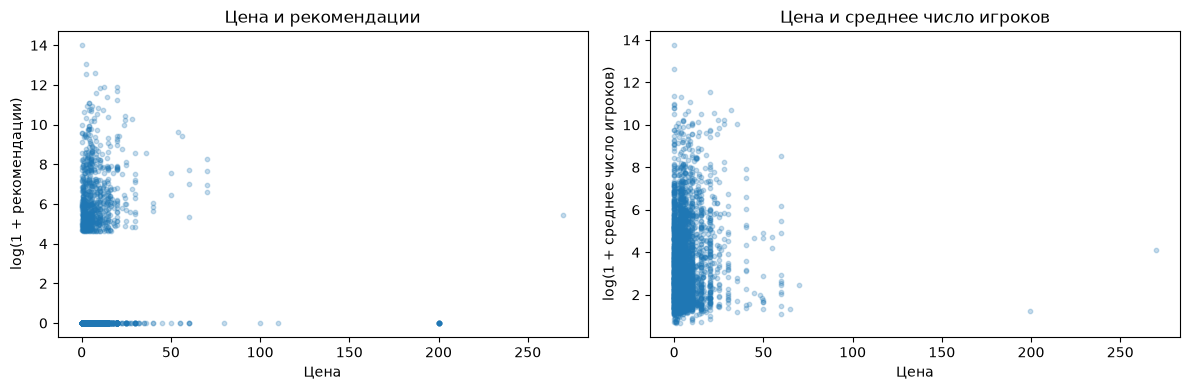

In [7]:
from scipy.stats import kruskal, mannwhitneyu, spearmanr


def show_p_value(value):
    return "< 1e-300" if value == 0 else f"{value:.3g}"


# Корреляции по цене, году выхода и доле положительных оценок.
correlation_pairs = [
    ("price", "recommendations"),
    ("release_year", "recommendations"),
    ("positive_share", "recommendations"),
    ("price", "avg_players_12m"),
    ("release_year", "avg_players_12m"),
    ("positive_share", "avg_players_12m"),
]

correlation_rows = []

for feature, target in correlation_pairs:
    sample = analysis_df[[feature, target]].dropna()
    sample = sample[(sample[feature] >= 0) & (sample[target] >= 0)]

    if len(sample) < 3:
        continue

    rho, p_value = spearmanr(sample[feature], sample[target])
    correlation_rows.append({
        "feature": feature,
        "target": target,
        "n": len(sample),
        "spearman_rho": rho,
        "p_value": p_value,
        "p_value_display": show_p_value(p_value),
    })

correlations = pd.DataFrame(correlation_rows)
correlations.to_csv(
    QUALITY_DIR / "correlations_2_4.csv",
    index=False,
    encoding="utf-8-sig",
)

# По жанрам отдельно показываем долю игр без рекомендаций
# и медиану числа рекомендаций среди игр, у которых они есть.
genre_data = analysis_df.dropna(
    subset=["primary_genre", "recommendations"]
).copy()
genre_data = genre_data[genre_data["recommendations"] >= 0]

genre_summary = (
    genre_data.groupby("primary_genre")
    .agg(
        games=("recommendations", "size"),
        zero_share=("recommendations", lambda values: (values == 0).mean()),
        median_all=("recommendations", "median"),
    )
)

positive_genres = (
    genre_data[genre_data["recommendations"] > 0]
    .groupby("primary_genre")["recommendations"]
    .agg(
        positive_games="size",
        median_positive="median",
    )
)

genre_summary = genre_summary.join(positive_genres)
genre_summary = genre_summary[genre_summary["games"] >= 30]
genre_summary = genre_summary.sort_values("games", ascending=False)

# Kruskal–Wallis сравнивает число рекомендаций только среди игр,
# у которых рекомендации больше нуля.
genre_groups = [
    np.log1p(group.loc[group["recommendations"] > 0, "recommendations"])
    .to_numpy()
    for _, group in genre_data.groupby("primary_genre")
    if (group["recommendations"] > 0).sum() >= 30
]

if len(genre_groups) >= 2:
    statistic, p_value = kruskal(*genre_groups)
    genre_test = pd.DataFrame([{
        "groups_tested": len(genre_groups),
        "kruskal_statistic": statistic,
        "p_value": p_value,
        "p_value_display": show_p_value(p_value),
    }])
else:
    genre_test = pd.DataFrame()

genre_summary.to_csv(
    QUALITY_DIR / "genre_summary_2_4.csv",
    encoding="utf-8-sig",
)
genre_test.to_csv(
    QUALITY_DIR / "genre_test_2_4.csv",
    index=False,
    encoding="utf-8-sig",
)

# Сравнение бесплатных и платных игр.
price_groups = analysis_df.dropna(
    subset=["price", "recommendations"]
).copy()
price_groups = price_groups[price_groups["price"] >= 0]
price_groups["price_group"] = np.where(
    price_groups["price"] == 0, "Free", "Paid"
)

price_rows = []

for target in ["recommendations", "avg_players_12m"]:
    sample = price_groups.dropna(subset=[target])
    free = sample.loc[sample["price_group"] == "Free", target]
    paid = sample.loc[sample["price_group"] == "Paid", target]

    if len(free) and len(paid):
        statistic, p_value = mannwhitneyu(
            free,
            paid,
            alternative="two-sided",
        )
        price_rows.append({
            "target": target,
            "free_games": len(free),
            "paid_games": len(paid),
            "median_free": free.median(),
            "median_paid": paid.median(),
            "mann_whitney_u": statistic,
            "p_value": p_value,
            "p_value_display": show_p_value(p_value),
        })

price_test = pd.DataFrame(price_rows)
price_test.to_csv(
    QUALITY_DIR / "free_vs_paid_2_4.csv",
    index=False,
    encoding="utf-8-sig",
)

display(correlations)
display(genre_test)
display(genre_summary.head(10))
display(price_test)

# Для каждого графика используется собственная доступная выборка.
recommendation_plot = analysis_df.dropna(
    subset=["price", "recommendations"]
)
recommendation_plot = recommendation_plot[
    (recommendation_plot["price"] >= 0)
    & (recommendation_plot["recommendations"] >= 0)
].sample(n=min(5_000, len(recommendation_plot)), random_state=42)

players_plot = analysis_df.dropna(
    subset=["price", "avg_players_12m"]
)
players_plot = players_plot[
    (players_plot["price"] >= 0)
    & (players_plot["avg_players_12m"] >= 0)
].sample(n=min(5_000, len(players_plot)), random_state=42)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].scatter(
    recommendation_plot["price"],
    np.log1p(recommendation_plot["recommendations"]),
    alpha=0.25,
    s=10,
)
axes[0].set(
    title="Цена и рекомендации",
    xlabel="Цена",
    ylabel="log(1 + рекомендации)",
)

axes[1].scatter(
    players_plot["price"],
    np.log1p(players_plot["avg_players_12m"]),
    alpha=0.25,
    s=10,
)
axes[1].set(
    title="Цена и среднее число игроков",
    xlabel="Цена",
    ylabel="log(1 + среднее число игроков)",
)

fig.tight_layout()
fig.savefig(OUTPUT_DIR / "price_popularity_2_4.png", dpi=150)
plt.show()
plt.close(fig)

## Модель машинного обучения

Для трёх показателей строится отдельный Random Forest: число рекомендаций Steam, доля положительных оценок и среднее число игроков. Используются цена, год выхода и основной жанр.

Для каждой модели берутся все доступные строки, но не более 150 000. В текущем запуске модели рекомендаций и доли положительных оценок используют все доступные строки; модель игроков ограничена охватом Steam Monthly Players.

Число рекомендаций и игроков моделируется на шкале `log1p`, а доля положительных оценок — на исходной шкале от 0 до 1. Метрики разных моделей напрямую между собой не сравниваются.

In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

FEATURES = ["price", "release_year", "primary_genre"]
TARGETS = ["recommendations", "positive_share", "avg_players_12m"]
MODEL_SAMPLE_LIMIT = 150_000

def fit_model(target):
    data = analysis_df[FEATURES + [target]].dropna().copy()
    data = data[(data["price"] >= 0) & (data[target] >= 0)]
    
    if target == "positive_share":
        data = data[data[target].between(0, 1)]
    
    available_rows = len(data)
    data = data.sample(
        n=min(MODEL_SAMPLE_LIMIT, available_rows),
        random_state=42,
    )
    
    X = data[FEATURES]
    y = (
        data[target]
        if target == "positive_share"
        else np.log1p(data[target])
    )

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.2,
        random_state=42,
    )

    preparation = ColumnTransformer([
        ("genre", OneHotEncoder(handle_unknown="ignore"), ["primary_genre"]),
        ("numeric", "passthrough", ["price", "release_year"]),
    ])

    model = Pipeline([
        ("prepare", preparation),
        ("forest", RandomForestRegressor(
            n_estimators=60,
            max_depth=14,
            min_samples_leaf=10,
            random_state=42,
            n_jobs=-1,
        )),
    ])

    baseline = DummyRegressor(strategy="median")

    started = time.perf_counter()
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    model_seconds = time.perf_counter() - started

    baseline.fit(X_train, y_train)
    baseline_predictions = baseline.predict(X_test)

    metrics = {
        "target": target,
        "available_rows": available_rows,
        "sample_rows": len(data),
        "test_rows": len(y_test),
        "model_mae": mean_absolute_error(y_test, predictions),
        "baseline_mae": mean_absolute_error(y_test, baseline_predictions),
        "model_rmse": np.sqrt(mean_squared_error(y_test, predictions)),
        "baseline_rmse": np.sqrt(
            mean_squared_error(y_test, baseline_predictions)
        ),
        "model_r2": r2_score(y_test, predictions),
        "training_seconds": model_seconds,
    }

    feature_names = model.named_steps["prepare"].get_feature_names_out()
    importance = pd.DataFrame({
        "target": target,
        "feature": feature_names,
        "importance": model.named_steps["forest"].feature_importances_,
    }).sort_values("importance", ascending=False)

    return metrics, importance


model_results = []
importance_results = []

for target in TARGETS:
    metrics, importance = fit_model(target)

    if metrics is not None:
        model_results.append(metrics)
        importance_results.append(importance)

model_metrics = pd.DataFrame(model_results)
feature_importance = pd.concat(importance_results, ignore_index=True)

model_metrics.to_csv(
    QUALITY_DIR / "model_metrics_2_4.csv",
    index=False,
    encoding="utf-8-sig",
)
feature_importance.to_csv(
    QUALITY_DIR / "feature_importance_2_4.csv",
    index=False,
    encoding="utf-8-sig",
)

display(model_metrics)
display(
    feature_importance.groupby("target", group_keys=False).head(10)
)

pd.DataFrame([{
    "stage": "analysis_2_4",
    "seconds": time.perf_counter() - analysis_start,
}]).to_csv(
    QUALITY_DIR / "processing_times_2_4.csv",
    index=False,
    encoding="utf-8-sig",
)

,target,available_rows,sample_rows,test_rows,model_mae,baseline_mae,model_rmse,baseline_rmse,model_r2,training_seconds
0,recommendations,142029,142029,28406,1.272159,0.984254,2.087538,2.581167,0.234621,2.527393
1,positive_share,82970,82970,16594,0.175486,0.178067,0.230375,0.244727,0.059354,1.152494
2,avg_players_12m,3551,3551,711,1.414098,1.496284,1.860854,2.072658,0.139563,0.092492


,target,feature,importance
0,recommendations,numeric__release_year,0.477753
1,recommendations,numeric__price,0.425654
2,recommendations,genre__primary_genre_Action,0.029398
3,recommendations,genre__primary_genre_Casual,0.027810
4,recommendations,genre__primary_genre_Adventure,0.013946
5,recommendations,genre__primary_genre_Indie,0.007777
6,recommendations,genre__primary_genre_Simulation,0.006803
7,recommendations,genre__primary_genre_RPG,0.006531
8,recommendations,genre__primary_genre_Strategy,0.001816
9,recommendations,genre__primary_genre_Racing,0.001628


## Выводы по анализу

В Steam цена слабо положительно связана с числом рекомендаций (ρ = 0,208; 150 466 игр), а год выхода — слабо отрицательно (ρ = −0,245). Связь доли положительных оценок с рекомендациями очень слабая (ρ = 0,042; 83 086 игр). Для среднего числа игроков связи также слабые: с ценой ρ = 0,093 и с годом выхода ρ = 0,102; с долей положительных оценок связь сильнее, но остаётся умеренной (ρ = 0,209). Это статистические ассоциации, а не доказательство причинного влияния.

Для среднего числа игроков за октябрь 2024 — сентябрь 2025 после фильтра по полноте осталось 3 557 игр с наблюдениями минимум за 9 из 12 месяцев. Этот показатель охватывает существенно меньше игр, чем каталог Steam, поэтому выводы о текущей активности аудитории ограничены.

Критерий Краскела — Уоллиса выявил различия в распределениях числа рекомендаций между 12 жанровыми группами среди игр с ненулевыми рекомендациями. Для бесплатных и платных игр медиана рекомендаций равна нулю в обеих группах, поэтому статистический результат критерия Манна — Уитни не следует трактовать как различие медиан. Среди игр с данными игроков медиана выше у бесплатных игр (31,12 против 17,55; 504 и 3 053 игры соответственно).

В Random Forest для рекомендаций R² составил 0,235; RMSE модели ниже базового (2,088 против 2,581), но MAE выше (1,272 против 0,984). Для доли положительных оценок и числа игроков преимущество над медианным базовым прогнозом по MAE и RMSE небольшое. Предсказательная способность моделей ограничена; важность признаков показывает вклад в прогноз и не означает причинного влияния.

В RAWG число оценок известно для 66 405 из 899 585 игр. Оно слабо связано с годом выпуска (ρ = −0,235; 62 929 игр) и рейтингом (ρ = 0,209; 18 675 игр). После выделения первого жанра критерий Краскела — Уоллиса сравнивает 19 жанровых групп; результат показывает различия распределений, но не указывает, какие пары жанров различаются.

Steam и RAWG анализируются отдельно: совпадения по названиям между источниками не подтверждены вручную. Результаты нельзя трактовать как анализ единого набора уникальных игр.